# Project 04: First Machine Learning Classifier (Titanic Survival)

## 1. Prediction Definition
**Goal:** Predict whether a passenger survived (`survived`, binary target: `1` = Survived, `0` = Did Not Survive) from their ticket class (`pclass`), gender (`sex`), `age`, and ticket `fare` (`pclass`, `sex`, `age`, `fare` are the features).

---

## 2. Prepare Data & Check Missing Values

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

from titanic_classifier import BLUE, ORANGE, SKY, SLATE, configure_style, load_and_prepare_data

configure_style()
raw, clean, y, X = load_and_prepare_data()

print("Raw Titanic shape:", raw.shape)
print("Missing values in selected columns:\n", raw[["survived", "pclass", "sex", "age", "fare"]].isna().sum())
print(f"\nClean shape after dropna(): {clean.shape} (dropped {len(raw) - len(clean)} rows missing age)")
print(f"Overall survival rate: {y.mean():.3f} ({y.sum()} survived, {(1 - y).sum()} did not survive)")
clean.head(5)

Raw Titanic shape: (891, 15)
Missing values in selected columns:
 survived      0
pclass        0
sex           0
age         177
fare          0
dtype: int64

Clean shape after dropna(): (714, 5) (dropped 177 rows missing age)
Overall survival rate: 0.406 (290 survived, 424 did not survive)


---
## 3. Stratified Train/Test Split (80% Train / 20% Unseen Test)

We separate the dataset before fitting any model (`test_size=0.2`, `random_state=42`, `stratify=y`) so both training and test sets preserve the `40.6%` survival rate.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"X_train: {X_train.shape} | Train survival rate: {y_train.mean():.3f}")
print(f"X_test:  {X_test.shape} | Test survival rate:  {y_test.mean():.3f}")

X_train: (571, 4) | Train survival rate: 0.406
X_test:  (143, 4) | Test survival rate:  0.406


---
## 4. Majority-Class Baseline vs. Decision Tree (`max_depth=4`)

First we compute the accuracy of always predicting the most common outcome (`0` = Did Not Survive), then fit `DecisionTreeClassifier(max_depth=4, random_state=42)` on `X_train, y_train` only.

In [3]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_acc = accuracy_score(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)

model = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, y_pred)
test_mse = mean_squared_error(y_test, y_pred)
brier_mse = mean_squared_error(y_test, y_prob)

print(f"Baseline Accuracy (most frequent): {baseline_acc:.4f} ({baseline_acc:.1%}) | MSE: {baseline_mse:.4f}")
print(f"Decision Tree Train Accuracy:      {train_acc:.4f} ({train_acc:.1%})")
print(f"Decision Tree Test Accuracy:       {test_acc:.4f} ({test_acc:.1%})  [+{(test_acc - baseline_acc)*100:.1f} pp over baseline]")
print(f"Decision Tree Test MSE (labels):   {test_mse:.4f} | Brier MSE (probs): {brier_mse:.4f}")

Baseline Accuracy (most frequent): 0.5944 (59.4%) | MSE: 0.4056
Decision Tree Train Accuracy:      0.8476 (84.8%)
Decision Tree Test Accuracy:       0.7972 (79.7%)  [+20.3 pp over baseline]
Decision Tree Test MSE (labels):   0.2028 | Brier MSE (probs): 0.1519


---
## 5. Evaluate on the Unseen Test Set: Confusion Matrix & Precision/Recall

Confusion Matrix (rows=Actual [0, 1], cols=Predicted [0, 1]):
[[72 13]
 [16 42]]
TN=72, FP=13, FN=16, TP=42

                 precision    recall  f1-score   support

Did Not Survive      0.818     0.847     0.832        85
       Survived      0.764     0.724     0.743        58

       accuracy                          0.797       143
      macro avg      0.791     0.786     0.788       143
   weighted avg      0.796     0.797     0.796       143


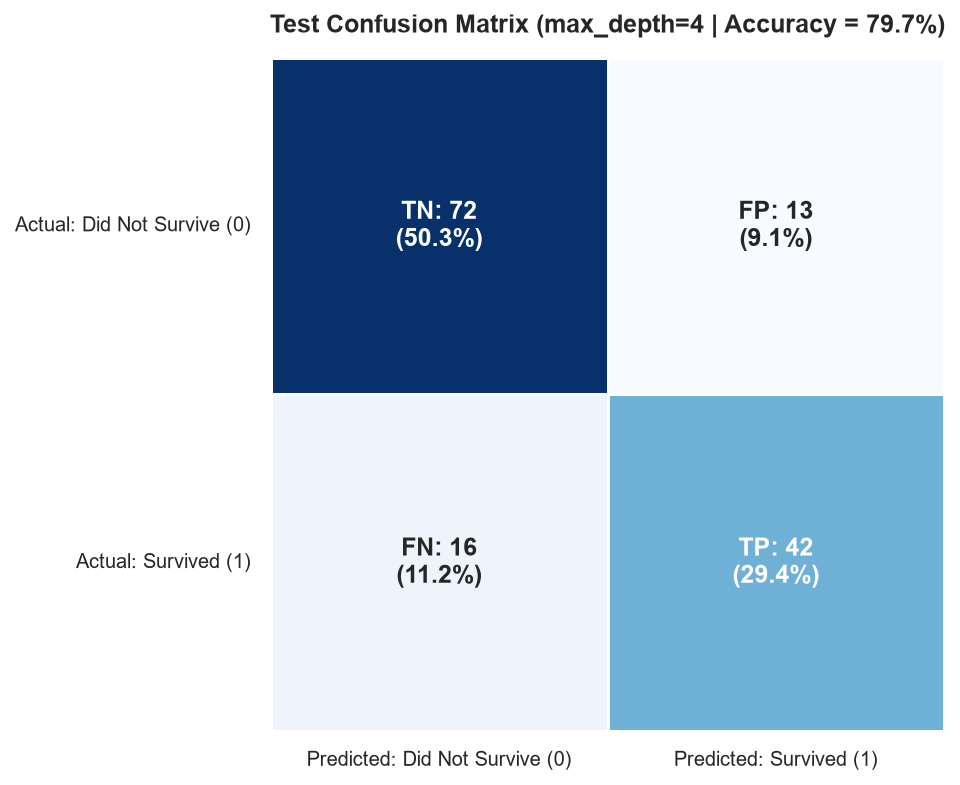

In [4]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("Confusion Matrix (rows=Actual [0, 1], cols=Predicted [0, 1]):")
print(cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}\n")
print(classification_report(y_test, y_pred, target_names=["Did Not Survive", "Survived"], digits=3))

fig, ax = plt.subplots(figsize=(7.6, 5.4))
total = cm.sum()
annot = np.empty_like(cm, dtype=object)
for r in range(2):
    for c in range(2):
        tag = ["TN", "FP", "FN", "TP"][r * 2 + c]
        annot[r, c] = f"{tag}: {cm[r, c]}\n({cm[r, c] / total * 100:.1f}%)"

sns.heatmap(
    cm, annot=annot, fmt="", cmap="Blues", cbar=False,
    linewidths=1.2, linecolor="white", square=True,
    annot_kws={"size": 12, "weight": "bold"},
    xticklabels=["Predicted: Did Not Survive (0)", "Predicted: Survived (1)"],
    yticklabels=["Actual: Did Not Survive (0)", "Actual: Survived (1)"],
    ax=ax,
)
ax.set_title(f"Test Confusion Matrix (max_depth=4 | Accuracy = {test_acc:.1%})", fontsize=12, pad=12)
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()

**What each of the four cells means (`n = 143` unseen passengers):**
- **TN = 72 (50.3%):** Passengers who did not survive and were correctly predicted as Did Not Survive.
- **FP = 13 (9.1%):** Passengers who did not survive, but the model falsely predicted Survived.
- **FN = 16 (11.2%):** Passengers who actually survived, but the model missed them and predicted Did Not Survive.
- **TP = 42 (29.4%):** Passengers who survived and were correctly predicted as Survived.

---
## 6. Feature Importances & Tree Structure

Feature Importances:
sex       0.5451
pclass    0.2350
age       0.1376
fare      0.0824


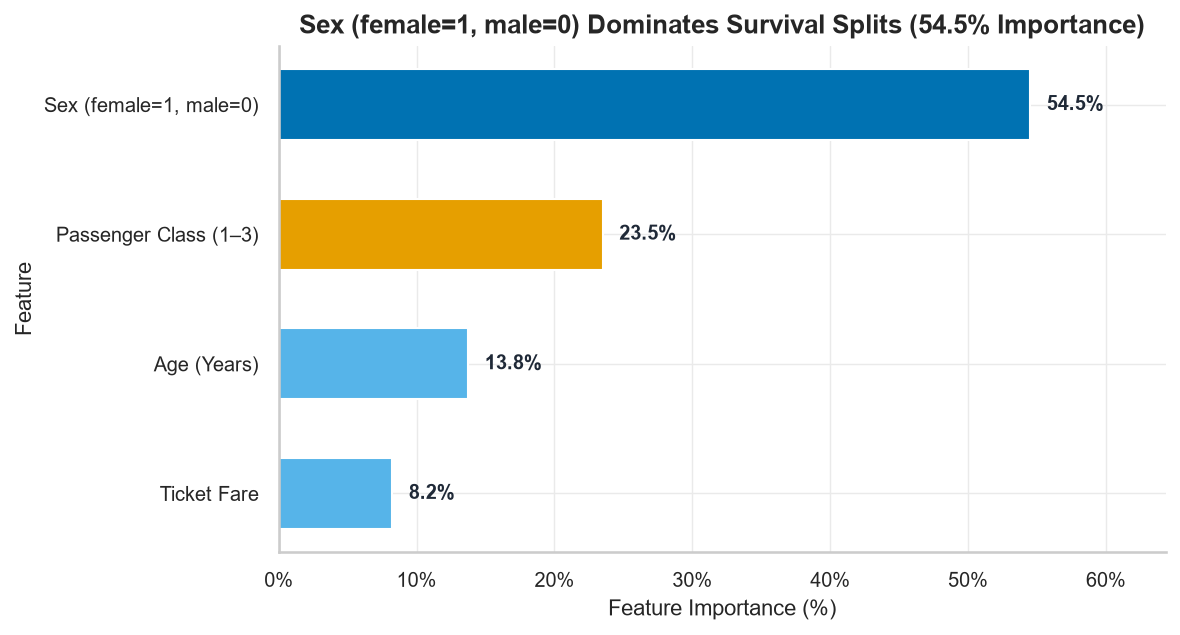

In [5]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Feature Importances:")
print(importances.round(4).to_string())

fig, ax = plt.subplots(figsize=(8.0, 4.4))
imp_sorted = importances.sort_values(ascending=True)
pretty = {"sex": "Sex (female=1, male=0)", "pclass": "Passenger Class (1–3)", "age": "Age (Years)", "fare": "Ticket Fare"}
labels = [pretty[k] for k in imp_sorted.index]
vals = imp_sorted.values * 100

bars = ax.barh(labels, vals, color=[SKY, SKY, ORANGE, BLUE], height=0.55, edgecolor="white")
for bar, v in zip(bars, vals):
    ax.text(v + 1.2, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%", va="center", fontsize=9.5, fontweight="bold", color=SLATE)

ax.set_xlim(0, max(vals) * 1.18)
ax.axvline(0, color="#444444", linewidth=1.0)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:.0f}%"))
ax.set(
    title=f"{labels[-1]} Dominates Survival Splits ({vals[-1]:.1f}% Importance)",
    xlabel="Feature Importance (%)",
    ylabel="Feature",
)
sns.despine(ax=ax)
plt.tight_layout()

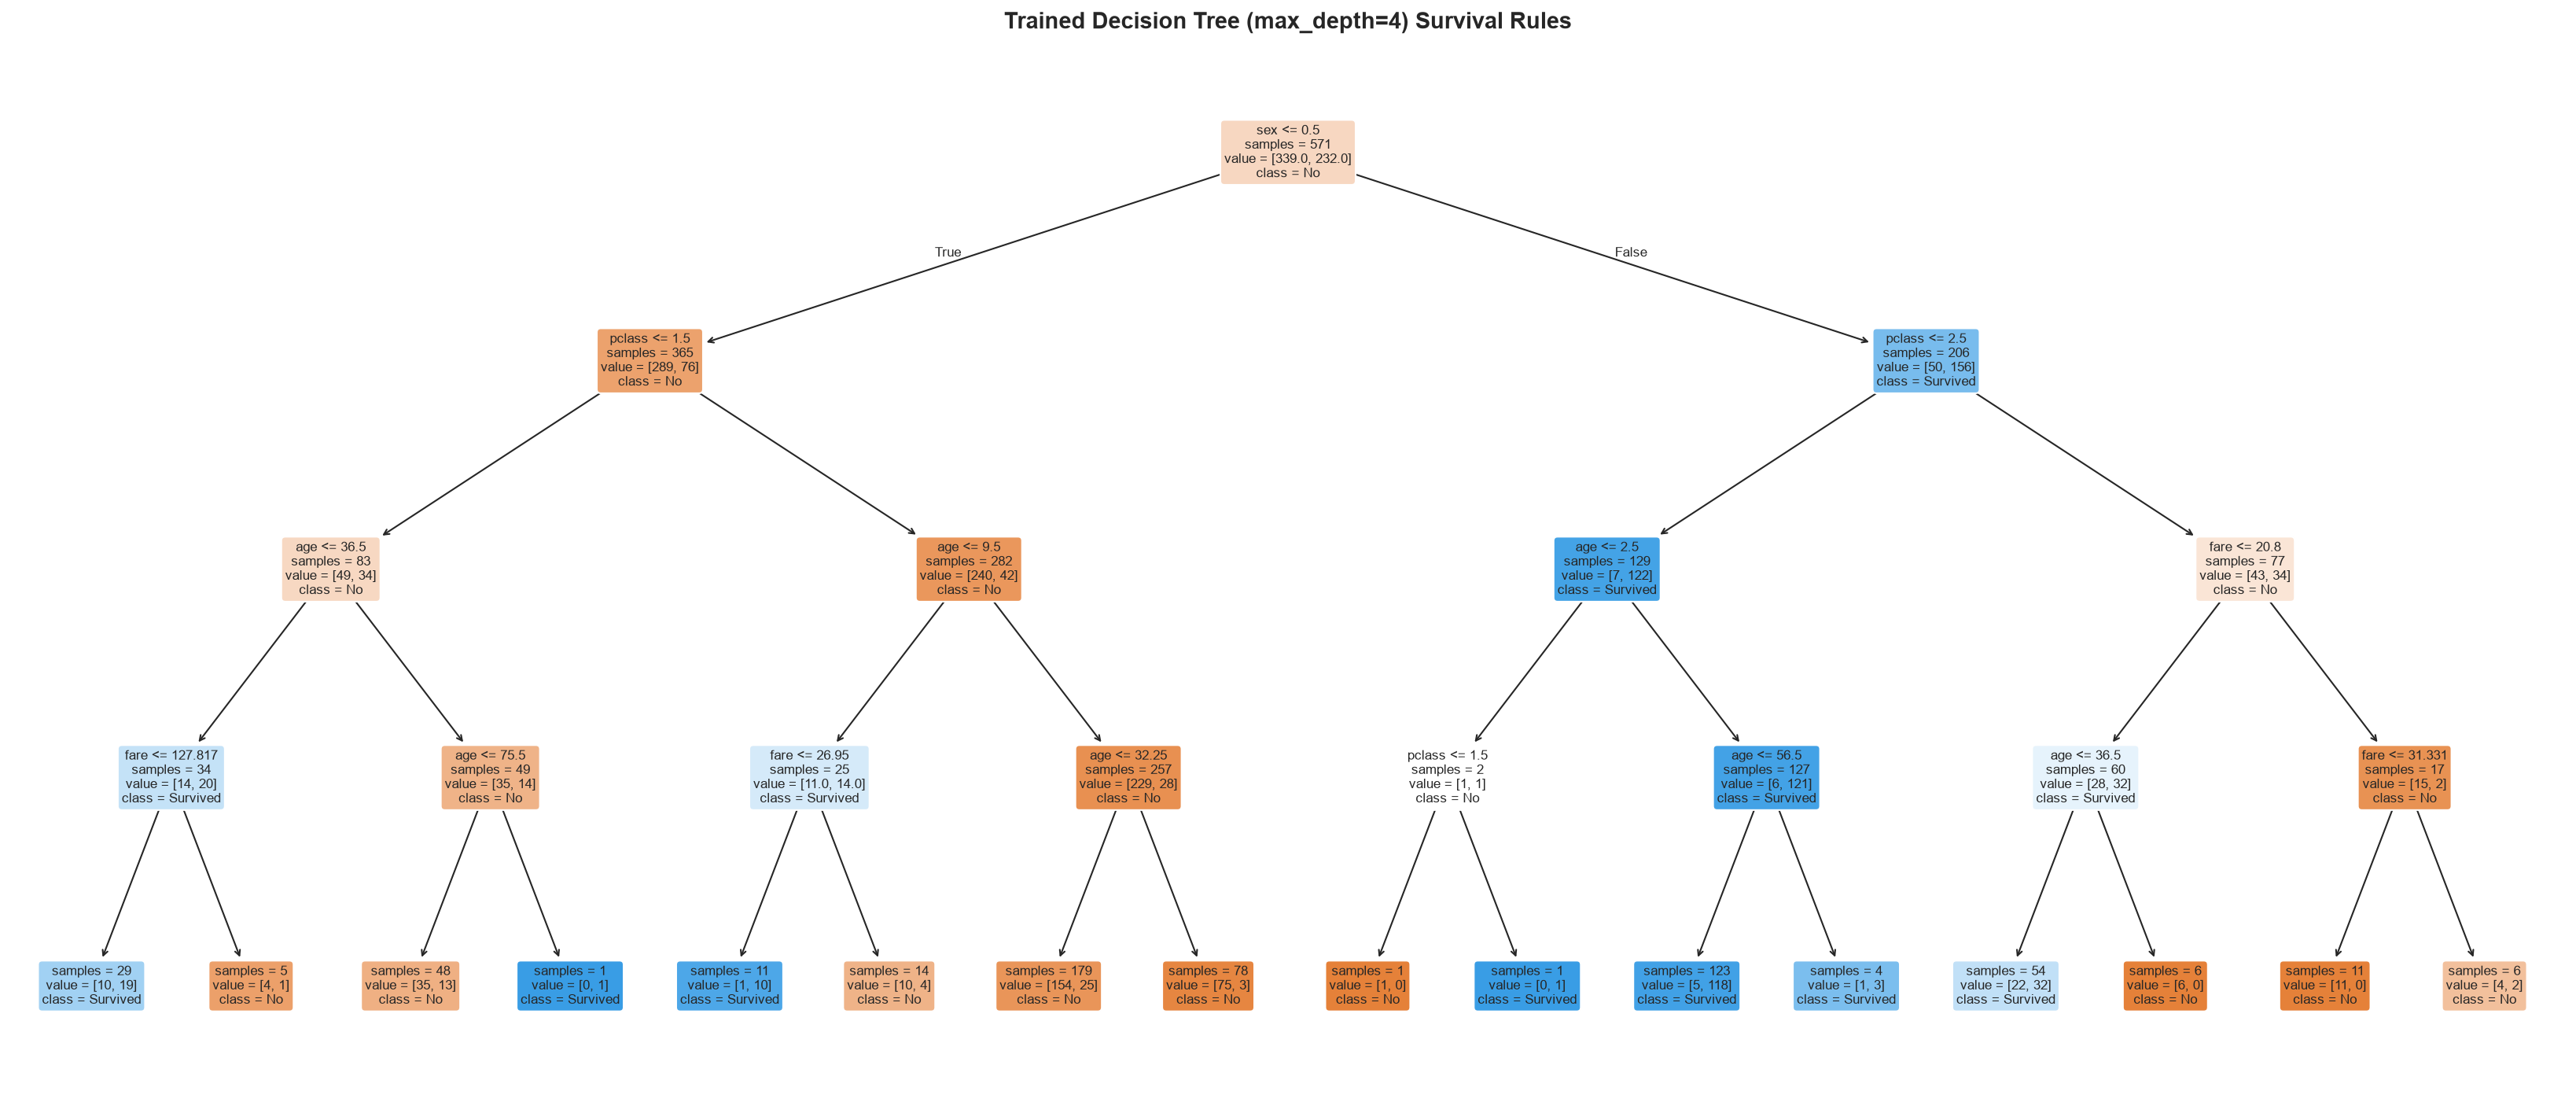

In [6]:
fig, ax = plt.subplots(figsize=(22, 9.5))
plot_tree(
    model,
    feature_names=list(X.columns),
    class_names=["No", "Survived"],
    filled=True, rounded=True, fontsize=8,
    proportion=False, impurity=False, ax=ax,
)
ax.set_title("Trained Decision Tree (max_depth=4) Survival Rules", fontsize=14, fontweight="bold", pad=12)
plt.tight_layout()

---
## 7. Testing `max_depth` (1 to 12) & Diagnosing Overfitting

 max_depth  train_accuracy  test_accuracy  gap_pp
         1          0.7793         0.7832    -0.4
         2          0.7951         0.7762     1.9
         3          0.8179         0.8112     0.7
         4          0.8476         0.7972     5.0
         5          0.8651         0.7622    10.3
         6          0.8827         0.7832     9.9
         7          0.9159         0.7832    13.3
         8          0.9247         0.7902    13.4
         9          0.9475         0.7692    17.8
        10          0.9562         0.7622    19.4
        11          0.9650         0.7692    19.6
        12          0.9685         0.7762    19.2


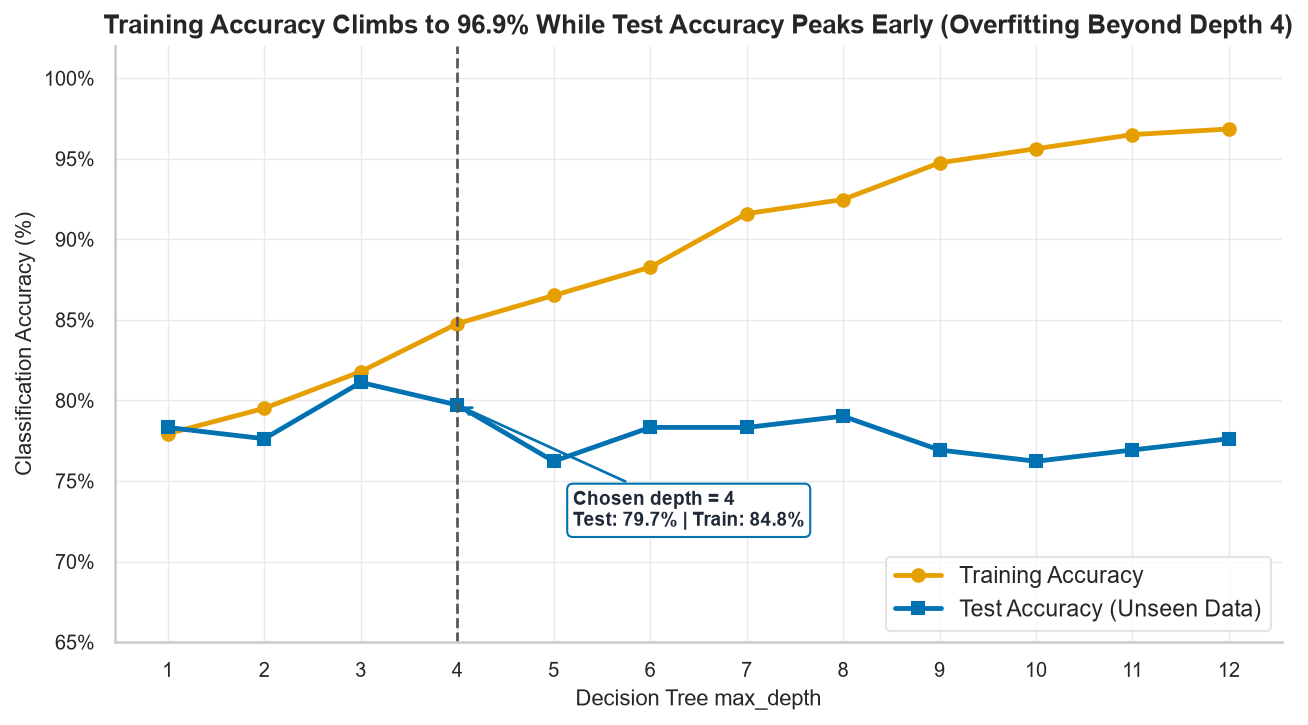

In [7]:
rows = []
for depth in range(1, 13):
    clf = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    rows.append({
        "max_depth": depth,
        "train_accuracy": accuracy_score(y_train, clf.predict(X_train)),
        "test_accuracy": accuracy_score(y_test, clf.predict(X_test)),
    })
depth_df = pd.DataFrame(rows)
depth_df["gap_pp"] = (depth_df["train_accuracy"] - depth_df["test_accuracy"]) * 100
print(depth_df.round({"train_accuracy": 4, "test_accuracy": 4, "gap_pp": 1}).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.8, 5.0))
ax.plot(depth_df["max_depth"], depth_df["train_accuracy"] * 100, marker="o", color=ORANGE, linewidth=2.3, label="Training Accuracy")
ax.plot(depth_df["max_depth"], depth_df["test_accuracy"] * 100, marker="s", color=BLUE, linewidth=2.3, label="Test Accuracy (Unseen Data)")

row4 = depth_df[depth_df["max_depth"] == 4].iloc[0]
ax.axvline(4, color="#555555", linestyle="--", linewidth=1.3)
ax.annotate(
    f"Chosen depth = 4\nTest: {row4['test_accuracy']:.1%} | Train: {row4['train_accuracy']:.1%}",
    xy=(4, row4["test_accuracy"] * 100),
    xytext=(5.2, row4["test_accuracy"] * 100 - 7.5),
    arrowprops={"arrowstyle": "->", "color": BLUE, "lw": 1.3},
    fontsize=9.2, fontweight="bold", color=SLATE,
    bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": BLUE},
)

ax.set_xticks(depth_df["max_depth"].tolist())
ax.set_ylim(65, 102)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:.0f}%"))
ax.set(
    title="Training Accuracy Climbs to 96.9% While Test Accuracy Peaks Early (Overfitting Beyond Depth 4)",
    xlabel="Decision Tree max_depth",
    ylabel="Classification Accuracy (%)",
)
ax.legend(loc="lower right")
sns.despine(ax=ax)
plt.tight_layout()

**Why very deep trees perform worse on new data:** As `max_depth` increases from 4 to 12, the tree keeps splitting small pockets of passengers until training accuracy reaches **96.9%**, memorizing random noise and individual outliers in the 571 training rows. Because those hyper-specific rules do not generalize to unseen passengers, test accuracy falls back to **77.6%** (a **19.2 percentage-point** generalization gap), whereas shallower trees (`max_depth` 3–4) capture broad, generalizable patterns (`81.1%` / `79.7%` test accuracy).

---

## 8. Summary & Honest Limitations

- **Accuracy vs. Baseline:** The depth-4 Decision Tree achieved **79.7% test accuracy** (`MSE = 0.2028` on labels, `0.1519` Brier MSE on probabilities), beating the **59.4%** majority-class baseline by **+20.3 percentage points**.
- **Top Drivers:** `sex` (`54.5%`) and `pclass` (`23.5%`) account for `78.0%` of total split importance, followed by `age` (`13.8%`) and `fare` (`8.2%`).
- **Honest Limitations:**
  1. **Small Dataset & Noisy Test Split (`n = 714`, test `n = 143`):** A single passenger changes test accuracy by `0.7` pp, so small test-score swings across depths partly reflect random sample noise.
  2. **177 Rows Dropped for Missing Age:** Dropping `19.9%` of the 891 passengers reduces sample size and may introduce selection bias if missing ages are concentrated among lower-class passengers.
  3. **Limited Features & Single-Tree Variance:** Only four features are included, and a single decision tree makes rigid axis-aligned splits that are less stable than ensemble models (e.g., Random Forest) or k-fold cross-validation.